In [1]:
import functools
import os

from ultralytics import YOLO
import pandas as pd

import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

TensorFlow version:  2.17.0


In [2]:
WEIGHTS_PTH = "results/filtered_v3_margin_15/weights/best.pt"

BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

CONF_TH = 0.35
IOU_TH = 0.5

args = dict(
    data=ALGOTEST_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

In [3]:
model = YOLO(WEIGHTS_PTH)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation: 100%|██████████| 75/75 [01:27<00:00,  1.16s/it]


                   all       9572      51930       0.91      0.872      0.905      0.601      0.922      0.883      0.917      0.915
   task    F1     P     R  MAP@50
0   box 0.890 0.910 0.872   0.905
1  pose 0.902 0.922 0.883   0.917


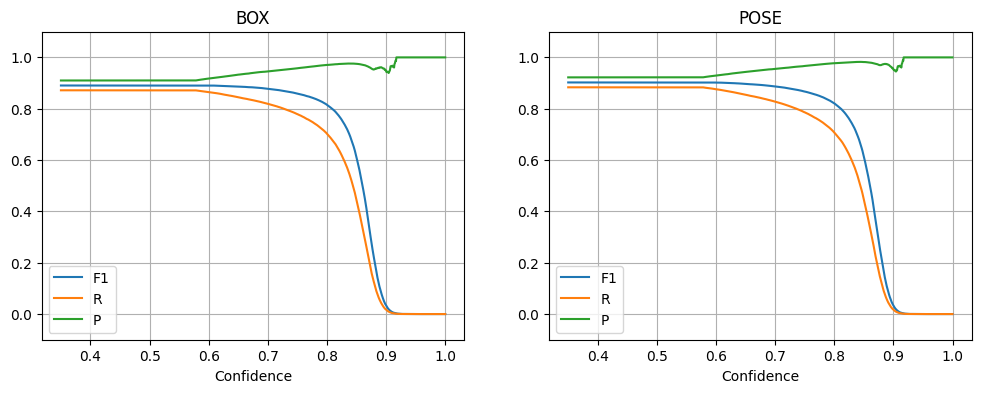

In [4]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
)

In [5]:
inferer = TFLiteInferer(
    yolo_pth="results/filtered_v3_margin_15/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="results/filtered_v3_margin_15/weights/head_saved_model/head_float32.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation: 100%|██████████| 75/75 [06:42<00:00,  5.36s/it]


                   all       9572      51930       0.91      0.864      0.903      0.594      0.923      0.877      0.918      0.915
   task    F1     P     R  MAP@50
0   box 0.886 0.910 0.864   0.903
1  pose 0.899 0.923 0.877   0.918


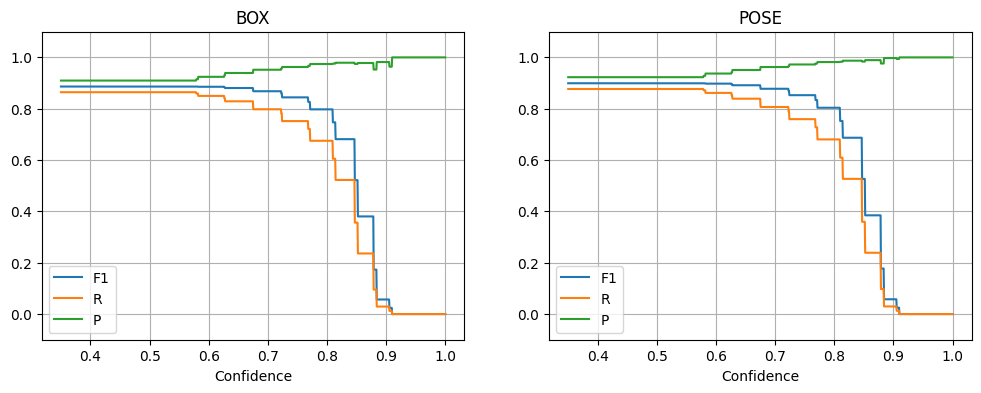

In [6]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args)
)

In [8]:
args["data"] = HOLDOUT_PTH

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
    False,
)

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [04:16<00:00,  1.49s/it]


                   all      22049     114004      0.923      0.879      0.917      0.627       0.94      0.895      0.936      0.934
   task    F1     P     R  MAP@50
0   box 0.901 0.923 0.879   0.917
1  pose 0.917 0.940 0.895   0.936


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [14:26<00:00,  5.01s/it]


                   all      22049     114004      0.924      0.865       0.91      0.617      0.942      0.882      0.929      0.926
   task    F1     P     R  MAP@50
0   box 0.894 0.924 0.865   0.910
1  pose 0.911 0.942 0.882   0.929
